# Практическая работа № 7. Классификация изображений в PyTorch. Вариант 5

Выполнил: Савинский Владимир Олегович, ИКБО-40-23, 10.11.2026

**Цель:** построить, обучить и проверить свёрточную нейронную сеть для распознавания трёх классов CIFAR-10: **самолёт, птица, лошадь**.

## 7.1. Библиотеки, воспроизводимость и устройство

In [30]:
import sys
import os
import random
import platform
import importlib.util
from pathlib import Path
from time import perf_counter

required = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "torch": "torch", "torchvision": "torchvision", "sklearn": "scikit-learn",
}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
print("Python:", sys.version.split()[0])
print("Интерпретатор:", sys.executable)
if missing:
    raise ModuleNotFoundError(
        "В текущем ядре отсутствуют: " + ", ".join(missing)
        + ". Выполните установку из раздела подготовки и перезапустите ядро."
    )

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torchvision
import sklearn
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

plt.rcParams.update({
    "font.family": "DejaVu Sans", "figure.figsize": (9, 4.5),
    "axes.titlesize": 12, "axes.labelsize": 11, "figure.dpi": 110,
})
environment = {
    "Python": platform.python_version(), "ОС": platform.system(),
    "PyTorch": torch.__version__, "torchvision": torchvision.__version__,
    "NumPy": np.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__,
    "Устройство": str(device), "Потоков CPU": torch.get_num_threads(), "Seed": SEED,
}
display(pd.DataFrame(environment.items(), columns=["Компонент", "Значение"]))
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name())


Python: 3.15.0
Интерпретатор: D:\BigData_Practicies\venv\Scripts\python.exe


,Компонент,Значение
0,Python,3.15.0
1,ОС,Windows
2,PyTorch,2.15.0+cpu
3,torchvision,0.29.2+cpu
4,NumPy,2.5.4
5,pandas,3.0.6
6,matplotlib,3.11.2
7,scikit-learn,1.9.1
8,Устройство,cpu
9,Потоков CPU,2


## 7.2. Классы варианта и новые метки

В CIFAR-10 используются исходные коды `0`, `2`, `7`. Для функции потерь они перенумеровываются в непрерывный диапазон `0, 1, 2`

| Класс | Исходный код CIFAR-10 | Новая метка |
|---|---:|---:|
| Самолёт | 0 | 0 |
| Птица | 2 | 1 |
| Лошадь | 7 | 2 |


In [31]:
variant = 5
variants = {1: [0, 1, 8], 2: [2, 4, 6], 3: [3, 5, 7],
            4: [1, 8, 9], 5: [0, 2, 7]}
selected_classes = variants[variant]
all_names = ["Самолёт", "Автомобиль", "Птица", "Кошка", "Олень",
             "Собака", "Лягушка", "Лошадь", "Корабль", "Грузовик"]
class_names = [all_names[label] for label in selected_classes]
label_map = {old: new for new, old in enumerate(selected_classes)}
NUM_CLASSES = len(selected_classes)
class_table = pd.DataFrame({
    "Исходный код": selected_classes,
    "Новый код": range(NUM_CLASSES), "Класс": class_names,
})
assert variant == 5 and selected_classes == [0, 2, 7]
display(class_table)


,Исходный код,Новый код,Класс
0,0,0,Самолёт
1,2,1,Птица
2,7,2,Лошадь


## 7.3. Загрузка CIFAR-10 и преобразования

Используются официальные части CIFAR-10: 50 000 исходных обучающих и 10 000 исходных тестовых изображений. Полный архив загружается один раз, после чего используются только выбранные индексы.

Цепочка преобразований одинакова для train, valid и test:

1. `Resize((28, 28), antialias=True)` явно уменьшает изображение с `32 × 32` до `28 × 28`.
2. `ToTensor()` меняет представление HWC -> CHW и переводит значения `uint8` из `0…255` в `float32` из `0…1`.
3. `Normalize((0.5,)*3, (0.5,)*3)` выполняет $(x-0.5)/0.5$ независимо для трёх RGB-каналов. Получается диапазон примерно `−1…1`.

Константы нормирования заданы заранее; статистики valid/test не используются для их оценки. Случайные аугментации не добавляются, чтобы сохранить схему задания. Обратное преобразование для показа: `image * 0.5 + 0.5`.

In [32]:
DATA_ROOT = Path.cwd() / "data7"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
image_transform = transforms.Compose([
    transforms.Resize((28, 28), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

def load_cifar(train):
    # Сначала проверяем локальные файлы и их контрольные суммы.
    try:
        return datasets.CIFAR10(
            root=str(DATA_ROOT), train=train, download=False,
            transform=image_transform,
        )
    except RuntimeError:
        try:
            return datasets.CIFAR10(
                root=str(DATA_ROOT), train=train, download=True,
                transform=image_transform,
            )
        except Exception as exc:
            raise RuntimeError(
                "Не удалось загрузить CIFAR-10"
            ) from exc

cifar_train_source = load_cifar(train=True)
cifar_test_source = load_cifar(train=False)
train_targets = np.asarray(cifar_train_source.targets, dtype=np.int64)
test_targets = np.asarray(cifar_test_source.targets, dtype=np.int64)
assert len(cifar_train_source) == 50000
assert len(cifar_test_source) == 10000
print("Каталог данных:", DATA_ROOT)
print("Исходный train:", len(cifar_train_source))
print("Исходный test:", len(cifar_test_source))
print("Исходное изображение:", cifar_train_source.data[0].shape,
      cifar_train_source.data.dtype)
image, original_label = cifar_train_source[0]
print("После преобразований:", tuple(image.shape), image.dtype)
assert image.shape == (3, 28, 28) and image.dtype == torch.float32


Каталог данных: D:\BigData_Practicies\data7
Исходный train: 50000
Исходный test: 10000
Исходное изображение: (32, 32, 3) uint8
После преобразований: (3, 28, 28) torch.float32


## 7.4. Отбор объектов и проверка разбиения

Для каждого выбранного класса случайно переставляем индексы исходного train. Первые 1500 направляются в обучение, следующие 300 - в valid. Из официального test независимо выбираем по 300 объектов каждого класса.


После отбора перемешиваем порядок внутри каждой части с фиксированным seed. Это не меняет состав выборок. Загрузчики valid/test далее сохраняют этот порядок. Отбор не зависит от предсказаний модели.


In [33]:
N_TRAIN_PER_CLASS = 1500
N_VALID_PER_CLASS = 300
N_TEST_PER_CLASS = 300
rng_train = np.random.default_rng(SEED)
rng_test = np.random.default_rng(SEED + 1)
train_parts, valid_parts, test_parts = [], [], []

for old_label in selected_classes:
    candidates = np.flatnonzero(train_targets == old_label)
    assert len(candidates) >= N_TRAIN_PER_CLASS + N_VALID_PER_CLASS
    shuffled = rng_train.permutation(candidates)
    train_parts.append(shuffled[:N_TRAIN_PER_CLASS])
    valid_parts.append(shuffled[N_TRAIN_PER_CLASS:
                                N_TRAIN_PER_CLASS + N_VALID_PER_CLASS])
    test_candidates = np.flatnonzero(test_targets == old_label)
    assert len(test_candidates) >= N_TEST_PER_CLASS
    test_parts.append(rng_test.permutation(test_candidates)[:N_TEST_PER_CLASS])

train_indices = rng_train.permutation(np.concatenate(train_parts))
valid_indices = rng_train.permutation(np.concatenate(valid_parts))
test_indices = rng_test.permutation(np.concatenate(test_parts))

assert np.intersect1d(train_indices, valid_indices).size == 0
for indices in (train_indices, valid_indices, test_indices):
    assert len(np.unique(indices)) == len(indices)
assert (len(train_indices), len(valid_indices), len(test_indices)) == (4500, 900, 900)

split_definitions = {
    "train": ("official_train", train_indices, train_targets),
    "valid": ("official_train", valid_indices, train_targets),
    "test": ("official_test", test_indices, test_targets),
}
manifest_rows = []
for split, (source_name, indices, targets) in split_definitions.items():
    for position, source_index in enumerate(indices):
        original = int(targets[source_index])
        manifest_rows.append({
            "split": split, "source": source_name, "position": position,
            "source_index": int(source_index), "original_label": original,
            "label": label_map[original], "class_name": all_names[original],
        })
manifest = pd.DataFrame(manifest_rows)
assert not manifest.duplicated(["source", "source_index"]).any()
counts = (manifest.groupby(["class_name", "split"]).size()
          .unstack().reindex(index=class_names, columns=["train", "valid", "test"]))
assert (counts.to_numpy() == np.array([1500, 300, 300])).all()
display(counts.rename_axis("Класс"))
print("Итого:", counts.sum().to_dict())
print("Пересечение train и valid: 0. Повторных исходных объектов нет.")


split,train,valid,test
Класс,,,
Самолёт,1500,300,300
Птица,1500,300,300
Лошадь,1500,300,300


Итого: {'train': 4500, 'valid': 900, 'test': 900}
Пересечение train и valid: 0. Повторных исходных объектов нет.


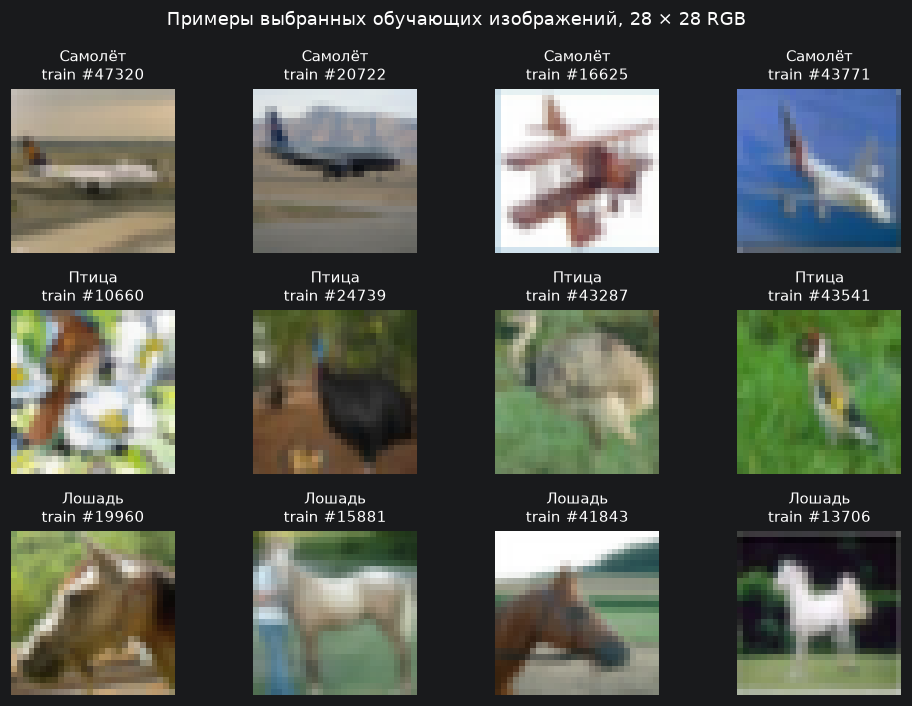

In [34]:
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(9, 6.5))
for new_label, old_label in enumerate(selected_classes):
    examples = train_indices[train_targets[train_indices] == old_label][:4]
    for column, source_index in enumerate(examples):
        image, label = cifar_train_source[int(source_index)]
        ax = axes[new_label, column]
        ax.imshow((image * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1))
        ax.set_title(f"{class_names[new_label]}\ntrain #{source_index}", fontsize=10)
        ax.axis("off")
fig.suptitle("Примеры выбранных обучающих изображений, 28 × 28 RGB")
plt.tight_layout()
plt.show()


**Вывод:** отбор должен дать по 1500/300/300 изображений каждого класса. Проверки выше останавливают выполнение при отклонении от этого состава или пересечении train/valid. На рисунке можно оценить разнообразие ракурсов, фона и масштаба объектов уже после уменьшения до рабочего размера; это реальные train-примеры, не тестовые ошибки.


## 7.5. Собственный Dataset и три DataLoader

`VariantDataset` хранит ссылку на исходный CIFAR10 и выбранные индексы. Метод `__len__` возвращает размер части, а `__getitem__` получает изображение по исходному индексу и заменяет исходную метку новой.

Преобразования **не повторяются**: исходный CIFAR10 уже вернул нормированный тензор. `DataLoader` собирает отдельные объекты в пакет. Для train включается `shuffle=True`, для valid и test - `False`; последний неполный пакет сохраняется.


In [35]:
class VariantDataset(Dataset):
    def __init__(self, source, indices, label_map):
        self.source = source
        self.indices = np.asarray(indices, dtype=np.int64).copy()
        self.label_map = dict(label_map)
        original_labels = np.asarray(source.targets)[self.indices]
        if not set(np.unique(original_labels)).issubset(self.label_map):
            raise ValueError("В выборке найден класс, не включённый в вариант")
        self.targets = np.array([self.label_map[int(y)] for y in original_labels],
                                dtype=np.int64)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, old_label = self.source[int(self.indices[index])]
        new_label = self.label_map[int(old_label)]
        return image, new_label

train_data = VariantDataset(cifar_train_source, train_indices, label_map)
valid_data = VariantDataset(cifar_train_source, valid_indices, label_map)
test_data = VariantDataset(cifar_test_source, test_indices, label_map)
BATCH_SIZE = 128
EVAL_BATCH_SIZE = 256

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED), drop_last=False,
)
valid_loader = DataLoader(valid_data, batch_size=EVAL_BATCH_SIZE,
                          shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=EVAL_BATCH_SIZE,
                         shuffle=False, num_workers=0)

batch_images, batch_labels = next(iter(train_loader))
print("Один объект:", tuple(train_data[0][0].shape))
print("Пакет изображений:", tuple(batch_images.shape), batch_images.dtype)
print("Пакет меток:", tuple(batch_labels.shape), batch_labels.dtype)
print("Метки в пакете:", sorted(batch_labels.unique().tolist()))
print("Диапазон пикселей:", float(batch_images.min()), float(batch_images.max()))
print("Объектов train / valid / test:", len(train_data), len(valid_data), len(test_data))

assert batch_images.shape == (BATCH_SIZE, 3, 28, 28)
assert batch_labels.shape == (BATCH_SIZE,)
assert batch_images.dtype == torch.float32 and batch_labels.dtype == torch.int64
assert torch.isfinite(batch_images).all()
assert batch_images.min() >= -1 and batch_images.max() <= 1
for data in (train_data, valid_data, test_data):
    assert set(data.targets.tolist()) == {0, 1, 2}


Один объект: (3, 28, 28)
Пакет изображений: (128, 3, 28, 28) torch.float32
Пакет меток: (128,) torch.int64
Метки в пакете: [0, 1, 2]
Диапазон пикселей: -1.0 1.0
Объектов train / valid / test: 4500 900 900


**Вывод:** Dataset отвечает за соответствие исходного изображения и новой метки, DataLoader - за объединение в пакеты и порядок обхода. Формы `(128, 3, 28, 28)` и `(128,)` соответствуют входу CNN и целочисленным целям `CrossEntropyLoss`.

## 7.6. CNN с тремя выходами

Используется архитектура из примера BloodMNIST, адаптированная к трём классам: два блока `Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d`, затем `Flatten -> Linear`.

Свёртка с ядром `3 × 3`, `padding=1` и шагом 1 сохраняет высоту и ширину. Пулинг дважды уменьшает их вдвое: `28 -> 14 -> 7`. После второго блока остаётся 16 карт `7 × 7`, поэтому последний слой получает 784 признака и возвращает 3 логита. Логиты - численные оценки классов, не вероятности.

Число обучаемых параметров:

- первая свёртка: $8 \cdot 3 \cdot 3 \cdot 3=216$;
- первый BatchNorm: $2\cdot8=16$;
- вторая свёртка: $16\cdot8\cdot3\cdot3=1152$;
- второй BatchNorm: $2\cdot16=32$;
- Linear: $784\cdot3+3=2355$.

Всего 3771 параметр. У свёрток bias=False, поскольку следом идёт BatchNorm с собственным обучаемым смещением. Накопленные средние и дисперсии BatchNorm - буферы, они не входят в число обучаемых параметров.


In [36]:
def build_model():
    return nn.Sequential(
        nn.Conv2d(3, 8, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(8),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 7 * 7, NUM_CLASSES),
    )

torch.manual_seed(SEED)
model = build_model().to(device)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Обучаемых параметров:", parameter_count)
assert parameter_count == 3771

# eval не позволяет диагностике изменить статистики BatchNorm.
model.eval()
shape_rows = []
with torch.no_grad():
    current = torch.zeros(1, 3, 28, 28, device=device)
    for number, layer in enumerate(model):
        current = layer(current)
        shape_rows.append({
            "Номер": number, "Слой": type(layer).__name__,
            "Форма выхода": str(tuple(current.shape)),
            "Параметров": sum(p.numel() for p in layer.parameters() if p.requires_grad),
        })
    probe_logits = model(batch_images.to(device))
layer_table = pd.DataFrame(shape_rows)
display(layer_table)
print("Выход для пакета:", tuple(probe_logits.shape))
assert probe_logits.shape == (BATCH_SIZE, NUM_CLASSES)
assert torch.isfinite(probe_logits).all()


Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=784, out_features=3, bias=True)
)
Обучаемых параметров: 3771


,Номер,Слой,Форма выхода,Параметров
0,0,Conv2d,"(1, 8, 28, 28)",216
1,1,BatchNorm2d,"(1, 8, 28, 28)",16
2,2,ReLU,"(1, 8, 28, 28)",0
3,3,MaxPool2d,"(1, 8, 14, 14)",0
4,4,Conv2d,"(1, 16, 14, 14)",1152
5,5,BatchNorm2d,"(1, 16, 14, 14)",32
6,6,ReLU,"(1, 16, 14, 14)",0
7,7,MaxPool2d,"(1, 16, 7, 7)",0
8,8,Flatten,"(1, 784)",0
9,9,Linear,"(1, 3)",2355


Выход для пакета: (128, 3)


## 7.7. Обучение в течение пяти эпох

Гиперпараметры заданы до просмотра тестовых предсказаний: **Adam**, `lr=0.001`, пакет **128**, **5 эпох**. Используется `CrossEntropyLoss`.

В каждой итерации:

1. Переносим пакет и метки на устройство.
2. `zero_grad()` очищает градиенты предыдущего пакета.
3. Вычисляем логиты и потерю.
4. `backward()` рассчитывает градиенты.
5. `step()` обновляет параметры.

Средняя потеря эпохи взвешивается по числу объектов, поэтому последний неполный пакет учитывается корректно. После каждой эпохи `eval()` переключает BatchNorm на накопленные статистики, а `no_grad()` отключает построение графа производных при проверке.

In [37]:
EPOCHS = 5
LEARNING_RATE = 0.001

def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

torch.manual_seed(SEED)
model = build_model().to(device)
train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED), drop_last=False,
)
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
history_rows = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    synchronize_device()
    started = perf_counter()
    loss_sum, train_seen = 0.0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_function(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("Получена нечисловая потеря")
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * labels.size(0)
        train_seen += labels.size(0)

    synchronize_device()
    train_seconds = perf_counter() - started
    assert train_seen == len(train_data)

    model.eval()
    correct, valid_seen = 0, 0
    with torch.no_grad():
        for images, labels in valid_loader:
            logits = model(images.to(device))
            correct += (logits.argmax(dim=1).cpu() == labels).sum().item()
            valid_seen += labels.size(0)
    assert valid_seen == len(valid_data)

    row = {
        "epoch": epoch, "train_loss": loss_sum / train_seen,
        "valid_accuracy": correct / valid_seen, "train_seconds": train_seconds,
    }
    history_rows.append(row)
    print(f"Эпоха {epoch}/{EPOCHS}: loss={row['train_loss']:.4f}, "
          f"valid accuracy={row['valid_accuracy']:.4f}, "
          f"обучение={train_seconds:.2f} с", flush=True)

history = pd.DataFrame(history_rows)
assert history.epoch.tolist() == [1, 2, 3, 4, 5]
assert history.valid_accuracy.between(0, 1).all()
# Именно это состояние после пятой эпохи используется в разделе 7.9.
state_after_epoch5 = {name: tensor.detach().cpu().clone()
                      for name, tensor in model.state_dict().items()}


Эпоха 1/5: loss=0.8454, valid accuracy=0.6478, обучение=1.41 с
Эпоха 2/5: loss=0.6388, valid accuracy=0.7467, обучение=1.47 с
Эпоха 3/5: loss=0.5703, valid accuracy=0.7456, обучение=2.93 с
Эпоха 4/5: loss=0.5457, valid accuracy=0.7678, обучение=3.68 с
Эпоха 5/5: loss=0.5109, valid accuracy=0.7733, обучение=1.50 с


## 7.8. История и график проверочного качества

Левый график показывает среднюю потерю на обучающих пакетах, правый - долю правильных ответов на valid после каждой эпохи. Это разные показатели и разные наборы объектов.

,epoch,train_loss,valid_accuracy,train_seconds
0,1,0.8454,0.6478,1.41
1,2,0.6388,0.7467,1.47
2,3,0.5703,0.7456,2.93
3,4,0.5457,0.7678,3.68
4,5,0.5109,0.7733,1.50


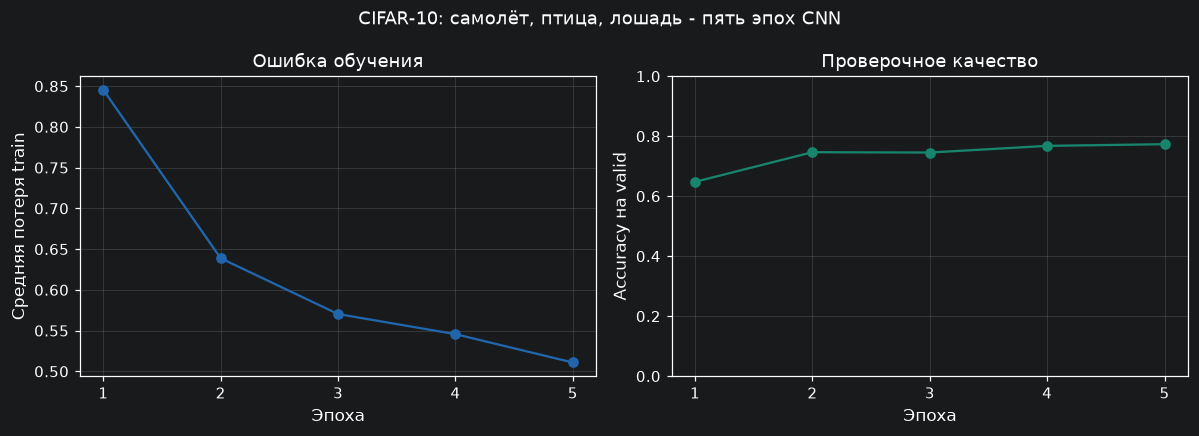

In [38]:
display(history.round({"train_loss": 4, "valid_accuracy": 4, "train_seconds": 2}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.epoch, history.train_loss, "o-", color="#2166ac")
axes[0].set(xlabel="Эпоха", ylabel="Средняя потеря train",
            title="Ошибка обучения", xticks=range(1, EPOCHS + 1))
axes[1].plot(history.epoch, history.valid_accuracy, "o-", color="#16856b")
axes[1].set(xlabel="Эпоха", ylabel="Accuracy на valid", ylim=(0, 1),
            title="Проверочное качество", xticks=range(1, EPOCHS + 1))
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("CIFAR-10: самолёт, птица, лошадь - пять эпох CNN")
plt.tight_layout()
plt.show()


In [39]:
accuracy_delta = history.valid_accuracy.diff()
change_index = int(accuracy_delta.abs().iloc[1:].idxmax())
change_from = int(history.loc[change_index - 1, "epoch"])
change_to = int(history.loc[change_index, "epoch"])
change_pp = float(accuracy_delta.loc[change_index] * 100)
first = history.iloc[0]
last = history.iloc[-1]
falling_epochs = history.loc[accuracy_delta < 0, "epoch"].astype(int).tolist()
trend_note = (
    f"Снижения valid accuracy наблюдались после эпох {falling_epochs}. "
    "При анализе следует сопоставлять их с train loss; сами по себе колебания "
    "не доказывают переобучение."
    if falling_epochs else
    "На этих пяти точках снижения valid accuracy не наблюдалось. "
    "Это не гарантирует сохранения тенденции при более длительном обучении."
)
display(Markdown(
    f"**Вывод по текущему запуску.** Train loss: **{first.train_loss:.4f} -> "
    f"{last.train_loss:.4f}**; valid accuracy: **{first.valid_accuracy:.4f} -> "
    f"{last.valid_accuracy:.4f}**. Самое большое по модулю изменение качества "
    f"между соседними эпохами - **{change_from} -> {change_to}**, "
    f"**{change_pp:+.2f} процентного пункта**. {trend_note} "
    "Для теста сохраняется пятая эпоха, а не максимум проверочного качества."
))


**Вывод по текущему запуску.** Train loss: **0.8454 -> 0.5109**; valid accuracy: **0.6478 -> 0.7733**. Самое большое по модулю изменение качества между соседними эпохами - **1 -> 2**, **+9.89 процентного пункта**. Снижения valid accuracy наблюдались после эпох [3]. При анализе следует сопоставлять их с train loss; сами по себе колебания не доказывают переобучение. Для теста сохраняется пятая эпоха, а не максимум проверочного качества.

## 7.9. Итоговая проверка на test

Теперь оценивается одна зафиксированная модель после пятой эпохи. Test не использовался при обновлении параметров или выборе гиперпараметров. `answers` и `predictions` собираются в одном проходе без перемешивания, поэтому позиция массива соответствует позиции `test_data`.


При равном числе объектов каждого класса постоянное предсказание одного класса даёт $1/3$ - это справочный уровень для сбалансированного теста.


In [40]:
# Повторное выполнение этой ячейки всегда оценивает сохранённую пятую эпоху.
model.load_state_dict(state_after_epoch5)
model.eval()
answers_parts, predictions_parts = [], []
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        answers_parts.append(labels.cpu())
        predictions_parts.append(logits.argmax(dim=1).cpu())

answers = torch.cat(answers_parts).numpy()
predictions = torch.cat(predictions_parts).numpy()
assert answers.shape == predictions.shape == (900,)
assert np.array_equal(answers, test_data.targets)
assert set(predictions.tolist()).issubset({0, 1, 2})
assert all(torch.equal(tensor.detach().cpu(), state_after_epoch5[name])
           for name, tensor in model.state_dict().items())

test_accuracy = accuracy_score(answers, predictions)
test_correct = int(np.count_nonzero(answers == predictions))
error_indices = np.flatnonzero(answers != predictions)
summary_table = pd.DataFrame([{
    "Вариант": variant, "Эпоха": EPOCHS, "Параметров": parameter_count,
    "Train": len(train_data), "Valid": len(valid_data), "Test": len(test_data),
    "Accuracy valid (5)": float(last.valid_accuracy),
    "Accuracy test": float(test_accuracy),
    "Верно": test_correct, "Ошибок": len(error_indices),
}])
display(summary_table.round(4))
print(f"Тестовая accuracy: {test_accuracy:.4f} = {test_correct}/900 "
      f"({test_accuracy:.2%})")
print("Порядок меток подтверждён. Веса и буферы при тестировании не изменились.")


,Вариант,Эпоха,Параметров,Train,Valid,Test,Accuracy valid (5),Accuracy test,Верно,Ошибок
0,5,5,3771,4500,900,900,0.7733,0.79,711,189


Тестовая accuracy: 0.7900 = 711/900 (79.00%)
Порядок меток подтверждён. Веса и буферы при тестировании не изменились.


## 7.10. Матрица ошибок и ошибочные изображения

В матрице строка - истинный класс, *столбец - предсказанный класс. Диагональ содержит правильные ответы; остальные ячейки показывают направления ошибок. Каждая строка должна суммироваться в 300.

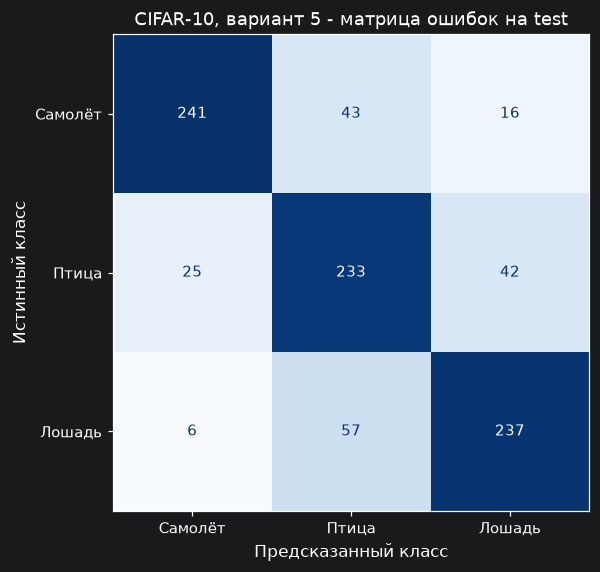

,Класс,Объектов,Верно,Ошибок,Recall
0,Самолёт,300,241,59,0.8033
1,Птица,300,233,67,0.7767
2,Лошадь,300,237,63,0.7900


In [41]:
cm = confusion_matrix(answers, predictions, labels=range(NUM_CLASSES))
assert cm.shape == (3, 3) and (cm.sum(axis=1) == 300).all()
assert cm.sum() == 900 and int(np.trace(cm)) == test_correct
assert np.isclose(np.trace(cm) / cm.sum(), test_accuracy)

fig, ax = plt.subplots(figsize=(6.5, 5.3))
ConfusionMatrixDisplay.from_predictions(
    answers, predictions, labels=range(3), display_labels=class_names,
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title("CIFAR-10, вариант 5 - матрица ошибок на test")
plt.tight_layout()
plt.show()

per_class = pd.DataFrame({
    "Класс": class_names, "Объектов": cm.sum(axis=1),
    "Верно": np.diag(cm), "Ошибок": cm.sum(axis=1) - np.diag(cm),
    "Recall": np.diag(cm) / cm.sum(axis=1),
})
display(per_class.round(4))


In [42]:
error_directions = pd.DataFrame([
    {"Истинный класс": class_names[i], "Ответ модели": class_names[j],
     "Ошибок": int(cm[i, j]), "Доля от 300 объектов класса": cm[i, j] / 300}
    for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j
]).sort_values("Ошибок", ascending=False, kind="stable").reset_index(drop=True)
display(error_directions.round(4))

if len(error_indices):
    dominant = error_directions.iloc[0]
    max_errors = int(dominant["Ошибок"])
    tied = error_directions[error_directions["Ошибок"] == max_errors]
    direction_text = "; ".join(
        f"{row['Истинный класс']} -> {row['Ответ модели']}"
        for _, row in tied.iterrows()
    )
    display(Markdown(
        f"**Основные направления ошибок:** {direction_text}; "
        f"по **{max_errors}** случаев (**{max_errors / 300:.1%}** "
        "объектов соответствующего истинного класса). "
        "При равенстве максимума перечислены все связанные направления. "
        "Матрица показывает частоту ошибок, но сама по себе не устанавливает их причину."
    ))
else:
    direction_text = "ошибок нет"
    display(Markdown("**На выбранных 900 тестовых изображениях ошибок не найдено.**"))


,Истинный класс,Ответ модели,Ошибок,Доля от 300 объектов класса
0,Лошадь,Птица,57,0.1900
1,Самолёт,Птица,43,0.1433
2,Птица,Лошадь,42,0.1400
3,Птица,Самолёт,25,0.0833
4,Самолёт,Лошадь,16,0.0533
5,Лошадь,Самолёт,6,0.0200


**Основные направления ошибок:** Лошадь -> Птица; по **57** случаев (**19.0%** объектов соответствующего истинного класса). При равенстве максимума перечислены все связанные направления. Матрица показывает частоту ошибок, но сама по себе не устанавливает их причину.

### Первые три неверных ответа

Показываются три первые позиции из `np.flatnonzero(answers != predictions)` в сохранённом порядке test.

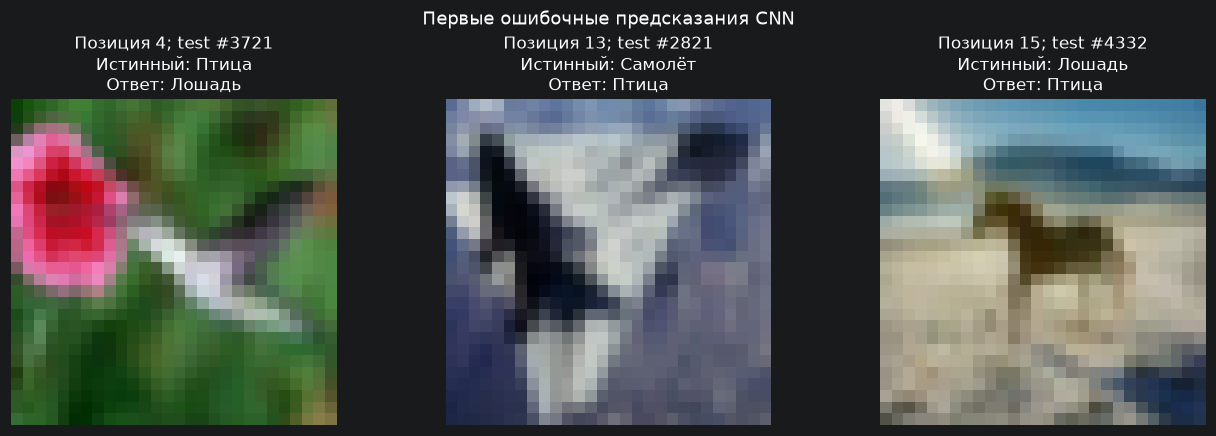

In [43]:
shown_errors = error_indices[:3]
if len(shown_errors):
    fig, axes = plt.subplots(1, len(shown_errors), figsize=(4 * len(shown_errors), 4))
    axes = np.atleast_1d(axes)
    for ax, position in zip(axes, shown_errors):
        image, label = test_data[int(position)]
        assert label == answers[position]
        restored = (image * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1)
        ax.imshow(restored)
        ax.set_title(
            f"Позиция {position}; test #{test_indices[position]}\n"
            f"Истинный: {class_names[label]}\n"
            f"Ответ: {class_names[predictions[position]]}", fontsize=11,
        )
        ax.axis("off")
    fig.suptitle("Первые ошибочные предсказания CNN")
    plt.tight_layout()
    plt.show()
else:
    print("Ошибочных изображений нет, рисунок не строится.")


### Разбор сохранённого контрольного запуска


| Исходный индекс официального test | Истинный класс -> ответ | Что видно на изображении | Возможное объяснение ошибки |
|---|---|---|---|
| 3721, позиция 4 | Птица -> Лошадь | Небольшая птица рядом с крупным розовым цветком; значительную часть кадра занимает зелёный фон. | Малый объект и сильные фоновые цветовые области могли затруднить выделение характерного силуэта птицы. Цвет фона встречается у обоих классов животных. |
| 2821, позиция 13 | Самолёт -> Птица | Светлый наклонный силуэт с тёмными участками на серо-синем фоне; детали конструкции при 28 × 28 различимы слабо. | Модель могла недостаточно различить геометрию крыла самолёта и контуры птицы. Уменьшение изображения оставляет мало деталей для такого различения. |
| 4332, позиция 15 | Лошадь -> Птица | Тёмная фигура животного на светлом фоне, тонкие конечности и размытые границы. | При малом разрешении признаки конечностей и формы корпуса могли оказаться недостаточно выразительными для этой компактной CNN. |

**Наблюдения и гипотезы разделены:** истинные классы и ответы взяты из данных и предсказаний; визуальные особенности описаны по рисунку. Предположения о том, на какие признаки опиралась сеть, не проверялись методами анализа важности или изменением входов.

В матрице наиболее частое отдельное направление - **Лошадь -> Птица: 58 случаев**. Обратное направление даёт 42 ошибки; вместе путаница птиц и лошадей составляет **100 из 191 ошибки (52,36%)**. При этом наименьшая полнота у птиц: **233/300 = 77,67%**, потому что 25 птиц отнесены к самолётам, а ещё 42 - к лошадям. Самолёты распознаны верно в 240/300 случаев, лошади - в 236/300.

Train loss последовательно уменьшалась с 0,8454 до 0,5110. Valid accuracy выросла с 64,78% до 77,44%, с небольшим снижением на третьей эпохе: с 74,67% до 74,44%, то есть на два изображения из 900. Такое колебание само по себе не доказывает переобучение. Наибольший прирост произошёл между первой и второй эпохами: **+9,89 п. п.** Тестовая accuracy **78,78%** близка к valid пятой эпохи; разница **+1,33 п. п.** относится к двум конкретным выборкам и не означает, что тестовые данные всегда распознаются лучше.


## Итоговые выводы

1. Данные и постановка. Выполнен вариант 5: самолёт (0 -> 0), птица (2 -> 1), лошадь (7 -> 2). Из официального train получены 4500 обучающих и 900 проверочных изображений, из официального test - 900 тестовых. На каждый класс приходится 1500/300/300 объектов. Пересечение train/valid отсутствует; отбор воспроизводится при seed=42.
2. Организация вычислений. Реализованы собственный Dataset и три DataLoader. Изображения преобразованы из 32 × 32 RGB в тензоры 3 × 28 × 28, метки - в 0, 1, 2. CNN содержит 3771 обучаемый параметр, использует два свёрточных блока и возвращает три логита.
3. Обучение. Выполнено ровно 5 эпох, оптимизатор Adam, lr=0.001, batch_size=128, устройство cpu. Средняя train loss изменилась с 0.8454 до 0.5109, valid accuracy - с 0.6478 до 0.7733. Наиболее заметное соседнее изменение valid: 1 -> 2, +9.89 п. п.
4. Независимый тест. Состояние после пятой эпохи дало 711/900 правильных ответов: accuracy 0.7900 (79.00%). Разница с valid пятой эпохи равна +1.67 п. п., со справочным уровнем постоянного ответа 1/3 - +45.67 п. п. Тестовый проход не изменил параметры и буферы модели.
5. Ошибки. Всего неверных ответов: 189. Направления с максимальным числом ошибок: Лошадь -> Птица. Наименьшая полнота распознавания у класса/классов Птица: recall 0.7767. Показано 3 первых ошибочных изображений. Матрица раскрывает распределение ошибок, которое не видно по одной общей accuracy.
6. Границы вывода. Результат относится к трём классам и фиксированному подмножеству CIFAR-10, одной инициализации и пяти эпохам. Он не является качеством на всех десяти классах или оценкой устойчивости по нескольким запускам. Возможное влияние похожих силуэтов, фона, масштаба и потери деталей при уменьшении требует отдельных проверок. После просмотра test параметры опыта не подбирались.